In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from copy import copy

### OU Process Simulation

In this notebook, we consider the scalar OU process

$$
dX(t) = -kX(t) + dW(t).
$$

We simulate 1,000 trajectories on the time interval $[0,1]$ using the Euler–Maruyama method, with $k = 1/2$, $\Delta t = 1/100$ and $x_0 = 1$.

In [ ]:
n_iter = 100
N_traj = 1000
k = 0.5
x0 = np.ones(N_traj)

def OU(N_traj, n_iter, k, x0):
    x = x0.copy()
    x_history = [x]
    dt = 1 / n_iter

    for _ in range(n_iter):
        x += np.random.normal(-k*dt*x, np.sqrt(dt), N_traj)
        x_history.append(x.copy())

    return np.array(x_history)


The theoretical mean and variance are given by

$$
\mathbb{E}[X(t)] = x_0 e^{-kt},
\qquad
\operatorname{Var}(X(t)) = \frac{1-e^{-2kt}}{2k}.
$$

Below I check if they agree with empirical estimates.

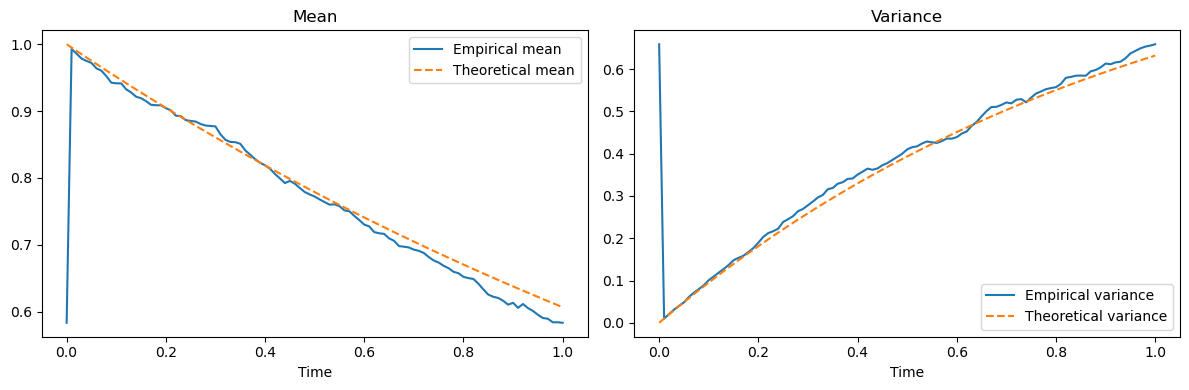

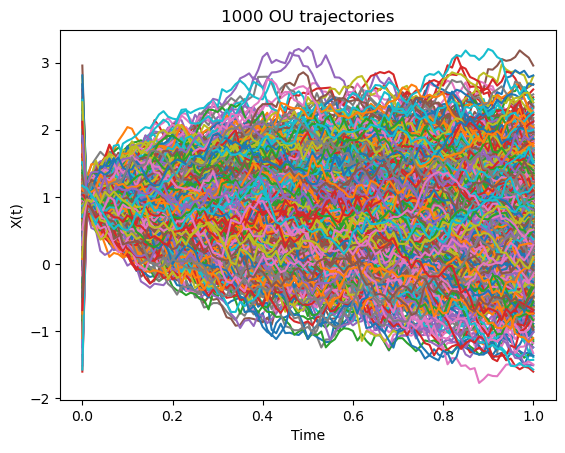

In [12]:
X = OU(N_traj, n_iter, k, x0)
t = np.linspace(0, 1, n_iter + 1)

t = np.linspace(0, 1, n_iter + 1)

emp_mean = np.mean(X, axis=1)
emp_var = np.var(X, axis=1)

theory_mean = np.exp(-k * t)
theory_var = (np.exp(2*-k*t) - 1) / (2*-k)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(t, emp_mean, label="Empirical mean")
ax[0].plot(t, theory_mean, "--", label="Theoretical mean")
ax[0].set_title("Mean")
ax[0].set_xlabel("Time")
ax[0].legend()

ax[1].plot(t, emp_var, label="Empirical variance")
ax[1].plot(t, theory_var, "--", label="Theoretical variance")
ax[1].set_title("Variance")
ax[1].set_xlabel("Time")
ax[1].legend()

plt.tight_layout()
plt.show()

plt.plot(t, X)
plt.xlabel("Time")
plt.ylabel("X(t)")
plt.title("1000 OU trajectories")
plt.show()